# Automated Pipeline Validation

This notebook demonstrates the `PipelineValidationError` system in `src/validation.py`.

**What it does:**
1. Loads the cleaned data from the SQLite store built by `src/storage.py`
2. Runs the validation checks on the real data (should all PASS)
3. Intentionally breaks the data in five different ways and shows that each one is caught with a clear error message
4. Visualizes the data-quality distributions that the checks rely on (so you can see *what* a passing/failing dataset looks like)

**The point of automated validation:** silent corruption is the worst kind of bug. By calling `validate_stage()` after every pipeline step, the pipeline halts immediately with a clear error pointing at the problem — instead of producing a broken `features` table that makes the model train on garbage.

## Setup

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.storage import load_from_db
from src.validation import (
    PipelineValidationError,
    validate_stage,
    check_required_columns,
    check_no_nulls,
    check_no_duplicates,
    check_no_future_dates,
    check_no_negative_prices,
    check_ohlc_consistency,
    check_row_count_in_range,
)

## Part 1 — Validate the real cleaned data

Load the cleaned data from SQLite via `load_from_db()` and run the full `after_clean` validation profile on it. Everything should pass.

In [2]:
df_clean = load_from_db()
print(f'Loaded cleaned_prices: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} cols')
df_clean.head(3)

Loaded cleaned_prices: 224,030 rows x 8 cols


,ticker,date,open,high,low,close,volume,label
0,AAPL,2015-02-17 00:00:00-05:00,31.8725,32.2200,31.7300,31.9575,252516820,1.0
1,AAPL,2015-02-18 00:00:00-05:00,31.9063,32.1950,31.8625,32.1788,179558052,0.0
2,AAPL,2015-02-19 00:00:00-05:00,32.1200,32.2575,32.0825,32.1125,149449524,1.0


In [3]:
validate_stage(df_clean, stage='after_clean')

  [OK] row count 224,030 in [200,000, 240,000]
--- after_clean: ALL CHECKS PASSED ---



## Part 2 — Intentionally broken inputs

Five tests. Each one takes the real dataframe, corrupts it in one specific way, and confirms the validator catches it with a clear message.

If a test *doesn't* raise `PipelineValidationError`, that's a bug in the validator — the test prints `TEST FAILED` and the cell continues so you can see all five outcomes.

In [4]:
def expect_failure(df, stage, description):
    """Run validate_stage and assert it raises PipelineValidationError."""
    print(f'\n>>> Test: {description}')
    try:
        validate_stage(df, stage=stage, verbose=False)
    except PipelineValidationError as e:
        print(f'    CAUGHT (good): {e}')
        return True
    except Exception as e:
        print(f'    TEST FAILED: raised {type(e).__name__} instead of PipelineValidationError: {e}')
        return False
    else:
        print(f'    TEST FAILED: no error was raised (the validator missed this!)')
        return False

results = []

In [5]:
# Test 1: nulls in a required column
df_bad = df_clean.copy()
df_bad.loc[df_bad.sample(50, random_state=0).index, 'close'] = np.nan
results.append(('nulls in close', expect_failure(df_bad, 'after_clean', 'inject 50 NaN values into close')))


>>> Test: inject 50 NaN values into close
    CAUGHT (good): Null values found in columns that must be non-null: {'close': 50}


In [6]:
# Test 2: duplicate (ticker, date) rows
df_bad = pd.concat([df_clean, df_clean.head(20)], ignore_index=True)
results.append(('duplicates', expect_failure(df_bad, 'after_clean', 'duplicate the first 20 rows')))


>>> Test: duplicate the first 20 rows
    CAUGHT (good): Found 40 duplicate rows on ['ticker', 'date']. First few: [{'ticker': 'AAPL', 'date': Timestamp('2015-02-17 00:00:00-0500', tz='America/New_York')}, {'ticker': 'AAPL', 'date': Timestamp('2015-02-18 00:00:00-0500', tz='America/New_York')}, {'ticker': 'AAPL', 'date': Timestamp('2015-02-19 00:00:00-0500', tz='America/New_York')}, {'ticker': 'AAPL', 'date': Timestamp('2015-02-20 00:00:00-0500', tz='America/New_York')}, {'ticker': 'AAPL', 'date': Timestamp('2015-02-23 00:00:00-0500', tz='America/New_York')}]


In [7]:
# Test 3: future-dated rows
df_bad = df_clean.copy()
df_bad.loc[df_bad.sample(3, random_state=1).index, 'date'] = pd.Timestamp('2099-01-01', tz='UTC')
results.append(('future dates', expect_failure(df_bad, 'after_clean', 'set 3 rows to dates in 2099')))


>>> Test: set 3 rows to dates in 2099
    CAUGHT (good): 3 rows have dates in the future (after 2026-10-10 19:58:06.563043+00:00). Examples: [Timestamp('2098-12-31 19:00:00-0500', tz='America/New_York'), Timestamp('2098-12-31 19:00:00-0500', tz='America/New_York'), Timestamp('2098-12-31 19:00:00-0500', tz='America/New_York')]


In [8]:
# Test 4: negative prices
df_bad = df_clean.copy()
idx = df_bad.sample(5, random_state=2).index
df_bad.loc[idx, 'low'] = -1.0
results.append(('negative prices', expect_failure(df_bad, 'after_clean', 'flip 5 low prices negative')))


>>> Test: flip 5 low prices negative


    CAUGHT (good): Non-positive prices found: {'low': 5}. Prices must be > 0 in all OHLC columns.


In [9]:
# Test 5: row count out of range (catastrophic data loss)
df_bad = df_clean.head(50_000).copy()
results.append(('row count too low', expect_failure(df_bad, 'after_clean', 'truncate to 50k rows (way below expected 200k+)')))


>>> Test: truncate to 50k rows (way below expected 200k+)
    CAUGHT (good): Too few rows: got 50,000, expected at least 200,000


In [10]:
# Bonus test 6: broken OHLC (high < open)
df_bad = df_clean.copy()
idx = df_bad.sample(10, random_state=3).index
df_bad.loc[idx, 'high'] = df_bad.loc[idx, 'open'] - 1  # high lower than open: impossible
results.append(('broken OHLC', expect_failure(df_bad, 'after_clean', 'set high < open on 10 rows')))


>>> Test: set high < open on 10 rows
    CAUGHT (good): OHLC inconsistency: 10 rows where high < max(open, close), 0 rows where low > min(open, close)


In [11]:
print('\n' + '=' * 60)
print('TEST SUMMARY')
print('=' * 60)
for name, passed in results:
    mark = 'PASS' if passed else 'FAIL'
    print(f'  [{mark}] {name}')
n_pass = sum(p for _, p in results)
print(f'\n{n_pass}/{len(results)} tests passed')


TEST SUMMARY
  [PASS] nulls in close
  [PASS] duplicates
  [PASS] future dates
  [PASS] negative prices
  [PASS] row count too low
  [PASS] broken OHLC

6/6 tests passed


## Part 3 — Visualize what the validator is checking

Graphs of the underlying distributions, so you can see *why* the checks are set up the way they are.

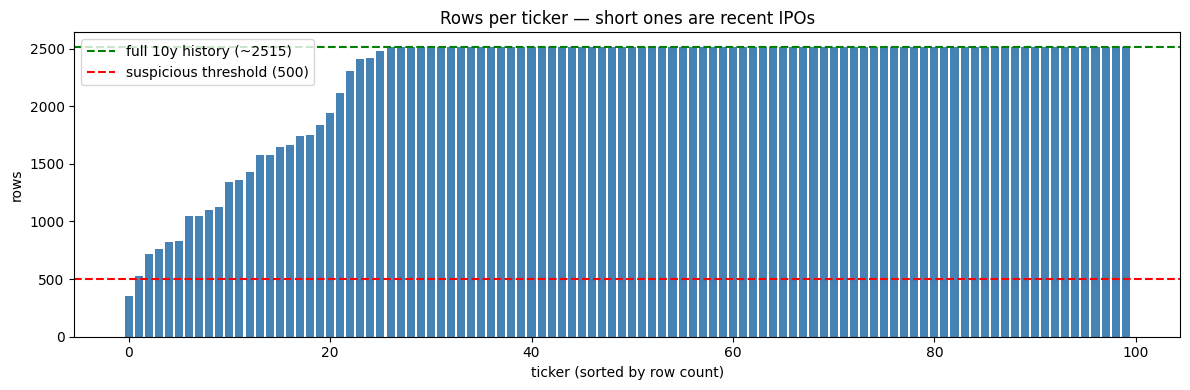

In [12]:
# Rows per ticker — outliers here are where the row-count and missing-data checks matter
per_ticker = df_clean.groupby('ticker').size().sort_values()
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(per_ticker)), per_ticker.values, color='steelblue')
ax.axhline(2515, color='green', linestyle='--', label='full 10y history (~2515)')
ax.axhline(500, color='red', linestyle='--', label='suspicious threshold (500)')
ax.set_xlabel('ticker (sorted by row count)')
ax.set_ylabel('rows')
ax.set_title('Rows per ticker — short ones are recent IPOs')
ax.legend()
plt.tight_layout()
plt.show()

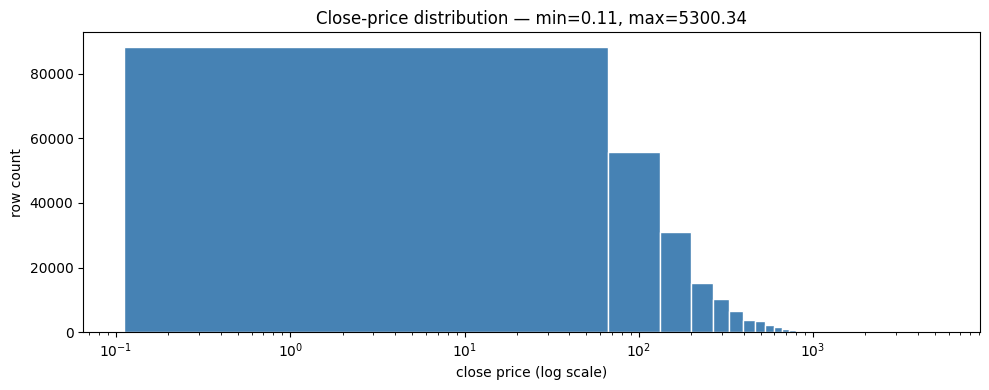

In [13]:
# Close-price distribution (log scale) — confirms no zero/negative prices made it through
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df_clean['close'], bins=80, color='steelblue', edgecolor='white')
ax.set_xscale('log')
ax.set_xlabel('close price (log scale)')
ax.set_ylabel('row count')
ax.set_title(f'Close-price distribution — min={df_clean["close"].min():.2f}, max={df_clean["close"].max():.2f}')
plt.tight_layout()
plt.show()

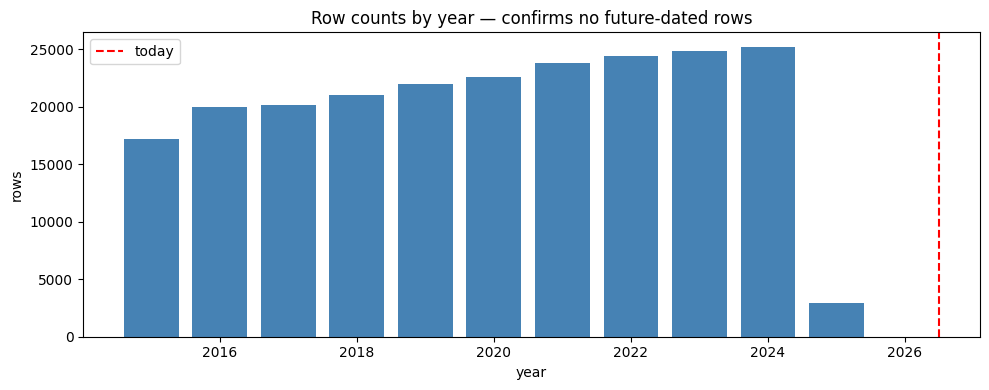

In [14]:
# Row counts over time — gaps would show calendar issues; future dates would stick out way to the right
by_year = df_clean.assign(year=pd.to_datetime(df_clean['date']).dt.year).groupby('year').size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.index, by_year.values, color='steelblue')
ax.axvline(pd.Timestamp.now().year + 0.5, color='red', linestyle='--', label='today')
ax.set_xlabel('year')
ax.set_ylabel('rows')
ax.set_title('Row counts by year — confirms no future-dated rows')
ax.legend()
plt.tight_layout()
plt.show()

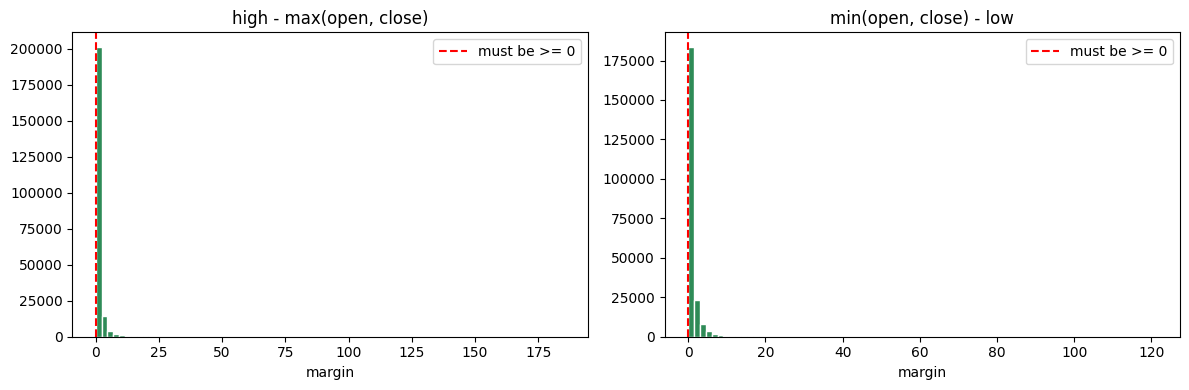

high_margin: min=0.0000, max=185.2300
low_margin:  min=0.0000, max=121.3300
Both minima should be >= 0. If not, the OHLC consistency check would fail.


In [15]:
# OHLC consistency: high - max(open, close) should always be >= 0
high_margin = df_clean['high'] - df_clean[['open', 'close']].max(axis=1)
low_margin = df_clean[['open', 'close']].min(axis=1) - df_clean['low']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(high_margin, bins=80, color='seagreen', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', label='must be >= 0')
axes[0].set_title('high - max(open, close)')
axes[0].set_xlabel('margin'); axes[0].legend()

axes[1].hist(low_margin, bins=80, color='seagreen', edgecolor='white')
axes[1].axvline(0, color='red', linestyle='--', label='must be >= 0')
axes[1].set_title('min(open, close) - low')
axes[1].set_xlabel('margin'); axes[1].legend()
plt.tight_layout()
plt.show()

print(f'high_margin: min={high_margin.min():.4f}, max={high_margin.max():.4f}')
print(f'low_margin:  min={low_margin.min():.4f}, max={low_margin.max():.4f}')
print('Both minima should be >= 0. If not, the OHLC consistency check would fail.')

## Part 4 — Where this runs in the pipeline

`src/pipeline.py` calls `validate_stage()` after loading and after cleaning:

```python
df = standardize(df)
check_schema(df)
validate_stage(df, stage="after_load")
...
df = remove_weekends_and_holidays(df)
df = remove_duplicate_rows(df)
df = validate_price_consistency(df)
...
validate_stage(df, stage="after_clean")
```

If any check fails, `PipelineValidationError` propagates up and stops the pipeline before any downstream step can use the bad data.